# A predictor of the microscope from one recording

`at_the_microscope/record_predictor.py` records, with no specimen, what is needed to predict what the microscope does
for any DAC values: kicks of CLA1 and CLA2 at every magnification row and camera length, the same lens values reached
by different routes, tests of the deflectors, and the beam itself over spot size and CL3. This notebook reads the
latest such recording and builds the predictor from it.

**Units.** Nothing here is in metres or radians. Lengths at the specimen are in CLA1 units (how far one DAC unit of
CLA1 shifts the beam), angles in CLA2 units, and everything on the camera in pixels. Two calibrations (a grating
image, gold rings) would turn those into nm and mrad afterwards, without refitting.

**What is fitted.** A TemGym column (`ElectromagneticLens` for the objective, IL1, IL2, IL3, PL1). Its lens positions
are not the real ones: the recording cannot tell them. It is a model of what the lenses do to the beam.

The recording here was made on the virtual NEOARM (`--simulated`), whose hidden optics are known, so the predictor
can also be checked on settings recorded afterwards.

In [1]:
import csv, json, os
from pathlib import Path

os.environ["JAX_PLATFORMS"] = "cpu"
import jax
import jax.numpy as jnp
import numpy as np
from jax.flatten_util import ravel_pytree
from scipy.optimize import least_squares

jax.config.update("jax_enable_x64", True)
from temgym_core.components import ElectromagneticLens, Plane
from temgym_core.constants import compute_Rc_from_voltage
from temgym_core.run import position_and_angle_response

RECORDING = sorted(Path("at_the_microscope/output/predictor").glob("*/table.csv"))[-1].parent
LENSES = ["IL1", "IL2", "IL3", "PL1"]
VOLTAGE = 200e3
PIXEL = 110e-6                      # only turns the model's metres into pixels; the deflector sizes absorb its value
table = list(csv.DictReader(open(RECORDING / "table.csv")))
console = json.loads((RECORDING / "console.json").read_text())
print(RECORDING)
print(len(table), "frames;", len(console), "console states")

at_the_microscope/output/predictor/2026-11-11_201956
1011 frames; 41 console states


## 1. Kicks: four frames each

A kick is the deflector + and - along its x, then + and - along its y. Half the difference of the two beam centres,
divided by the kick, is the response: how far one DAC unit displaces the beam on the camera (px per unit, x + iy).
Where the beam started cancels.

In [2]:
def centre(row):
    return complex(float(row["beam_x_px"]), float(row["beam_y_px"])) if row["beam_usable"] == "True" else np.nan


def number(text, default=np.nan):
    return float(text) if text not in ("", None) else default


kicks, i = [], 0
pattern = [("x", "1"), ("x", "-1"), ("y", "1"), ("y", "-1")]
while i < len(table):
    four = table[i:i + 4]
    if table[i]["role"] == "deflected" and [(r["direction"], r["sign"]) for r in four] == pattern:
        first, kick = four[0], float(four[0]["kick"])
        kicks.append(dict(
            stage=first["stage"], mode=first["function_mode"], row=int(first["mode_row"]), deflector=first["deflector"],
            kick=kick, lenses=[float(first[n]) for n in LENSES], setting=first["setting"], test=first["test"],
            reached=first["reached"], lens=first["lens"], swing=number(first["swing"]), change=number(first["change"]),
            spot=int(first["spot"]), cl3=float(first["CL3"]),
            along_x=(centre(four[0]) - centre(four[1])) / (2 * kick), along_y=(centre(four[2]) - centre(four[3])) / (2 * kick),
            middle=np.mean([centre(r) for r in four])))
        i += 4
    else:
        i += 1
usable = [k for k in kicks if np.isfinite(abs(k["along_x"])) and np.isfinite(abs(k["along_y"]))]
print(len(kicks), "kicks;", len(kicks) - len(usable), "with a frame where the beam was not usable")
kicks = usable
for stage in ["history", "kicks", "deflectors"]:
    print(f"   {stage}: {sum(k['stage'] == stage for k in kicks)}")

204 kicks; 3 with a frame where the beam was not usable
   history: 27
   kicks: 145
   deflectors: 29


## 2. How well a displacement repeats

In the history stage the same lens values were reached again and again. After a swing of 3000 units or more from
below, the lenses should be in the same state each time, so the scatter of those displacements is how well a
displacement repeats. It is the unit every misfit below is counted in.

In [3]:
history = [k for k in kicks if k["stage"] == "history"]
same = np.array([k["along_x"] * k["kick"] for k in history if k["reached"] == "from below" and k["swing"] >= 3000])
SCATTER_PX = max(float(np.sqrt(np.mean(np.abs(same - same.mean()) ** 2))), 0.005)
print(f"{len(same)} repeats of a displacement of {abs(same.mean()):.1f} px: scatter {SCATTER_PX:.4f} px")

8 repeats of a displacement of 60.0 px: scatter 0.0219 px


## 3. History: does the route to a lens value matter?

Each lens went away by a swing and came back, once from below and once from above. If a lens's field lags behind its
DAC value, the response differs between the two. Dividing that difference by how much the response changes per DAC
unit of the lens (from the +-1000 steps of the kicks stage, at the same row) gives the lag in DAC units.

In [4]:
start_row = history[0]["row"]
steps = {(k["lens"], k["change"]): k for k in kicks if k["stage"] == "kicks" and k["mode"] == "MAG"
         and k["row"] == start_row and k["deflector"] == "CLA1" and k["lens"]}
at_the_row = next(k for k in kicks if k["stage"] == "kicks" and k["mode"] == "MAG" and k["row"] == start_row
                  and k["deflector"] == "CLA1" and not k["lens"])
steps.update({(name, 0.0): at_the_row for name in LENSES})           # the row itself: a step of 0
lags = {}
print(f"at MAG {start_row}x; lag = half the difference between coming from above and from below, in DAC units")
print(f"{'lens':>5} {'swing':>6} {'response differs by':>20} {'lag (DAC units)':>16} {'beam centre differs by':>23}")
for name in LENSES:
    changes = sorted(c for (l, c) in steps if l == name)
    if len(changes) < 2:
        continue
    per_unit = (steps[name, changes[-1]]["along_x"] - steps[name, changes[0]]["along_x"]) / (changes[-1] - changes[0])
    for swing in sorted({k["swing"] for k in history if k["lens"] == name}):
        below = next(k for k in history if k["lens"] == name and k["swing"] == swing and k["reached"] == "from below")
        above = next(k for k in history if k["lens"] == name and k["swing"] == swing and k["reached"] == "from above")
        difference = above["along_x"] - below["along_x"]
        lag = float((difference * np.conj(per_unit)).real / abs(per_unit) ** 2 / 2)
        lags[name, swing] = lag
        print(f"{name:>5} {swing:6.0f} {abs(difference) * below['kick']:17.3f} px {lag:16.2f} "
              f"{abs(above['middle'] - below['middle']):20.2f} px")
print(f"(a displacement repeats to {SCATTER_PX:.3f} px)")

at MAG 40000x; lag = half the difference between coming from above and from below, in DAC units
 lens  swing  response differs by  lag (DAC units)  beam centre differs by
  IL1    300             0.014 px             0.57                 0.00 px
  IL1   3000             0.047 px             1.99                 0.01 px
  IL1  12000             0.091 px             3.81                 0.02 px
  IL2    300             0.005 px             0.22                 0.00 px
  IL2   3000             0.011 px             0.42                 0.00 px
  IL2  12000             0.087 px             3.83                 0.01 px
  IL3    300             0.001 px             0.03                 0.00 px
  IL3   3000             0.012 px             0.72                 0.00 px
  IL3  12000             0.058 px             4.02                 0.00 px
  PL1    300             0.006 px            -0.08                 0.01 px
  PL1   3000             0.009 px             0.69                 0.01 px
  PL

The recording script brings IL1-PL1 to every setting from 2000 units below. With that, every setting has the same
lag, which a fit cannot tell from a small constant change of the DAC values: the fit below needs no history term.
The lags above say how wrong a setting would be if it were reached another way.

## 4. The deflectors

Is the displacement proportional to the kick? Does the response change with CL3, or with the spot size?

In [5]:
tests = [k for k in kicks if k["stage"] == "deflectors"]
for deflector in ["CLA1", "CLA2"]:
    sized = [k for k in tests if k["test"] == "kick size" and k["deflector"] == deflector]
    if not sized:
        continue
    reference = sized[-1]["along_x"]
    print(f"{deflector} ({sized[0]['mode']} {sized[0]['row']}): response against the kick's size, relative to the largest kick")
    for k in sized:
        print(f"   kick {k['kick']:6.0f} ({abs(k['along_x']) * k['kick']:6.1f} px): {100 * (abs(k['along_x'] / reference) - 1):+6.2f} %, "
              f"turned {np.degrees(np.angle(k['along_x'] / reference)):+5.2f} deg")
    for test, label in [("CL3", "CL3 changed by"), ("spot", "spot index")]:
        chosen = [k for k in tests if k["test"] == test and k["deflector"] == deflector]
        print(f"{deflector}: response against {test}, relative to the largest kick above")
        for k in chosen:
            value = k["change"] if test == "CL3" else k["spot"]
            print(f"   {label} {value:6.0f} (CL3 {k['cl3']:.0f}): {100 * (abs(k['along_x'] / reference) - 1):+6.2f} %, "
                  f"turned {np.degrees(np.angle(k['along_x'] / reference)):+5.2f} deg")

CLA1 (MAG 40000): response against the kick's size, relative to the largest kick
   kick     66 (   7.8 px):  -0.03 %, turned +0.02 deg
   kick    133 (  15.7 px):  -0.01 %, turned +0.02 deg
   kick    333 (  39.4 px):  +0.01 %, turned -0.00 deg
   kick    667 (  78.9 px):  +0.00 %, turned -0.00 deg
   kick   1335 ( 157.8 px):  +0.00 %, turned +0.00 deg
CLA1: response against CL3, relative to the largest kick above
   CL3 changed by   -300 (CL3 33276):  -0.00 %, turned -0.00 deg
   CL3 changed by   -150 (CL3 33426):  -0.00 %, turned -0.00 deg
   CL3 changed by    150 (CL3 33726):  -0.01 %, turned -0.01 deg
   CL3 changed by    300 (CL3 33876):  +0.00 %, turned +0.02 deg
CLA1: response against spot, relative to the largest kick above
   spot index      0 (CL3 40772):  -0.00 %, turned -0.00 deg
   spot index      1 (CL3 35774):  +0.00 %, turned +0.00 deg
   spot index      2 (CL3 33575):  +0.01 %, turned -0.01 deg
   spot index      3 (CL3 32385):  -0.02 %, turned -0.01 deg
   spot index

## 5. Rotation gives each lens's ampere-turns

A magnetic lens turns the image in proportion to its ampere-turns, whatever its field's shape. The turn of the
response between the -1000 and +1000 steps of a lens gives its ampere-turns per DAC unit.

In [6]:
turn_per_ampere_turn = float(compute_Rc_from_voltage(VOLTAGE))
ampere_turns_per_unit = []
for name in LENSES:
    changes = sorted(c for (l, c) in steps if l == name)
    turn = np.angle(steps[name, changes[-1]]["along_x"] / steps[name, changes[0]]["along_x"]) / (changes[-1] - changes[0])
    ampere_turns_per_unit.append(turn / turn_per_ampere_turn)
    print(f"{name}: the image turns {np.degrees(turn) * 1000:+.3f} degrees per 1000 DAC units = "
          f"{ampere_turns_per_unit[-1]:+.4f} ampere-turns per unit")
ampere_turns_per_unit = np.array(ampere_turns_per_unit)

IL1: the image turns -1.739 degrees per 1000 DAC units = -0.0797 ampere-turns per unit
IL2: the image turns -1.742 degrees per 1000 DAC units = -0.0798 ampere-turns per unit
IL3: the image turns -1.749 degrees per 1000 DAC units = -0.0801 ampere-turns per unit
PL1: the image turns +1.748 degrees per 1000 DAC units = +0.0801 ampere-turns per unit


## 6. The TemGym column and the fit

A ray leaving the specimen at position x with angle theta lands on the camera at A x + B theta. A and B (complex:
size and rotation) depend only on the lens values, and come from TemGym's `position_and_angle_response` of the
column. A CLA1 kick changes x, so the beam is displaced by A times the shift per unit; a CLA2 kick changes theta, so
by B times the tilt per unit.

**Fitted:** half of the magnification rows and camera lengths (every other one), and the lens steps at the middle
rows. **Kept back:** the other rows, and the lens steps at the lowest and highest rows that have them.

**Held** (the recording cannot tell them): the PL1-to-camera gap and the size of one CLA1 unit. Their values only
set the model's internal metres.

In [7]:
def column(numbers, dac):
    """TemGym components from the specimen to the camera, for IL1, IL2, IL3, PL1 at these DAC values."""
    z = jnp.cumsum(jnp.exp(numbers["log_gaps"]))        # objective, IL1, IL2, IL3, PL1, camera
    objective = ElectromagneticLens(z=z[0], turns=1.0, current=1.0, Gc=jnp.exp(numbers["log_objective_Gc"]))
    lenses = [ElectromagneticLens(z=z[i + 1], turns=numbers["ampere_turns_per_unit"][i], current=dac[i],
                                  Gc=jnp.exp(numbers["log_Gc"][i]), Tc=jnp.exp(numbers["log_Tc"][i])) for i in range(4)]
    return [objective, *lenses, Plane(z=z[5])]


a_and_b = jax.jit(jax.vmap(lambda numbers, dac: position_and_angle_response(column(numbers, dac), voltage=VOLTAGE),
                           in_axes=(None, 0)))


def axes(deflector):
    """A deflector's x and y axes at the specimen (complex), per DAC unit."""
    x_axis = jnp.exp(deflector["log_size"] + 1j * deflector.get("x_angle", 0.0))
    return x_axis, x_axis * (deflector["y_axis"][0] + 1j * deflector["y_axis"][1])


def predicted_response(numbers, data):
    """px per DAC unit along each deflector's x and y, for every kick of ``data``."""
    a, b = a_and_b(numbers["lenses"], data["lenses"])
    (shift_x, shift_y), (tilt_x, tilt_y) = axes(numbers["CLA1"]), axes(numbers["CLA2"])
    on_camera = jnp.exp(1j * numbers["camera_rotation"]) / PIXEL
    return (on_camera * jnp.where(data["is_tilt"], b * tilt_x, a * shift_x),
            on_camera * jnp.where(data["is_tilt"], b * tilt_y, a * shift_y))


def as_arrays(chosen):
    return dict(lenses=np.array([k["lenses"] for k in chosen]), is_tilt=np.array([k["deflector"] == "CLA2" for k in chosen]),
                kick=np.array([k["kick"] for k in chosen]), along_x=np.array([k["along_x"] for k in chosen]),
                along_y=np.array([k["along_y"] for k in chosen]))


recorded = [k for k in kicks if k["stage"] == "kicks"]
rows = {mode: sorted({k["row"] for k in recorded if k["mode"] == mode}) for mode in ["MAG", "DIFF"]}
with_steps = {mode: sorted({k["row"] for k in recorded if k["mode"] == mode and k["lens"]}) for mode in rows}
middle_steps = {mode: with_steps[mode][len(with_steps[mode]) // 2] if len(with_steps[mode]) > 2 else with_steps[mode][0]
                for mode in rows}


def is_fitted(k):
    if k["lens"]:
        return k["row"] == middle_steps[k["mode"]] or len(with_steps[k["mode"]]) == 1
    return rows[k["mode"]].index(k["row"]) % 2 == 0


fitted, kept_back = [k for k in recorded if is_fitted(k)], [k for k in recorded if not is_fitted(k)]
data = as_arrays(fitted)
print(f"{len(fitted)} kicks fitted, {len(kept_back)} kept back")
print("fitted rows:   ", {m: [r for r in rows[m] if rows[m].index(r) % 2 == 0] for m in rows})
print("lens steps fitted at", middle_steps, "; kept back at", {m: [r for r in with_steps[m] if r != middle_steps[m]] for m in rows})

64 kicks fitted, 81 kept back
fitted rows:    {'MAG': [8000, 12000, 20000, 30000, 50000, 80000, 120000, 200000, 300000, 500000], 'DIFF': [15, 25, 40, 60, 100, 150]}
lens steps fitted at {'MAG': 40000, 'DIFF': 40} ; kept back at {'MAG': [8000, 200000], 'DIFF': [100]}


In [8]:
HELD_GAP, HELD_CLA1_SIZE = np.log(0.34), np.log(3e-10)


def with_held(free):
    lenses = dict(free["lenses"], log_gaps=jnp.r_[free["lenses"]["log_gaps"], HELD_GAP])
    return dict(free, lenses=lenses, CLA1=dict(free["CLA1"], log_size=HELD_CLA1_SIZE))


def misfits(values, as_numbers):
    """Predicted minus measured displacement along x and y, in units of the repeat scatter."""
    along_x, along_y = predicted_response(with_held(as_numbers(values)), data)
    misfit = jnp.concatenate([(along_x - data["along_x"]), (along_y - data["along_y"])]) * jnp.tile(data["kick"], 2) / SCATTER_PX
    return jnp.concatenate([misfit.real, misfit.imag])


def fit(start):
    start_list, as_numbers = ravel_pytree(start)
    if "compiled" not in fit.__dict__:                   # compile once; every start has the same layout
        fit.compiled = (jax.jit(lambda values: misfits(values, as_numbers)),
                        jax.jit(jax.jacfwd(lambda values: misfits(values, as_numbers))))
    result = least_squares(fit.compiled[0], np.asarray(start_list), jac=fit.compiled[1], method="lm",
                           xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=300)
    return dict(numbers=with_held(as_numbers(result.x)), chi2=float(result.fun @ result.fun),
                dof=len(result.fun) - len(result.x))


middle_row = np.array(next(k["lenses"] for k in fitted if k["mode"] == "MAG" and k["row"] == middle_steps["MAG"]))


def random_start(rng):
    ampere_turns = np.abs(ampere_turns_per_unit) * middle_row
    v_star = 239e3
    lenses = dict(ampere_turns_per_unit=ampere_turns_per_unit,
                  log_gaps=np.log([0.002, 0.1, 0.1, 0.1, 0.15]) + rng.normal(0, 0.6, 5),
                  log_objective_Gc=np.log(v_star / 0.002) + rng.normal(0, 0.7),
                  log_Gc=np.log(v_star / (0.02 * ampere_turns ** 2)) + rng.normal(0, 1.0, 4),
                  log_Tc=np.log(0.003 / ampere_turns) + rng.normal(0, 1.0, 4))
    start = dict(lenses=lenses, camera_rotation=0.0, CLA1=dict(y_axis=np.array([0.0, -1.0])),
                 CLA2=dict(log_size=np.log(1e-5), x_angle=0.0, y_axis=np.array([0.0, -1.0])))
    # size the tilt and turn the camera so the start is in the right region
    shift, tilt = ~data["is_tilt"], data["is_tilt"]
    seen = np.asarray(predicted_response(with_held(start), data)[0])
    strong = np.abs(data["along_x"]) * data["kick"] > 10
    start["CLA2"]["log_size"] += float(np.log(np.median(np.abs(data["along_x"][tilt & strong]) / np.abs(seen[tilt & strong]))))
    rotation = np.angle(np.vdot(seen[shift & strong], data["along_x"][shift & strong]))
    start["camera_rotation"] = float(rotation)
    start["CLA2"]["x_angle"] = float(np.angle(np.vdot(seen[tilt & strong], data["along_x"][tilt & strong])) - rotation)
    return start


STARTS = int(os.environ.get("STARTS", 40))
rng = np.random.default_rng(0)
fits = []
for _ in range(STARTS):
    try:
        result = fit(random_start(rng))
    except Exception:
        continue
    if np.isfinite(result["chi2"]):
        fits.append(result)
fits.sort(key=lambda f: f["chi2"])
best = fits[0]
numbers = best["numbers"]
print(f"{len(fits)} fits. The best five (chi2/dof 1 would be: fits to the repeat scatter):")
for f in fits[:5]:
    gaps_mm = np.exp(np.asarray(f["numbers"]["lenses"]["log_gaps"])) * 1e3
    print(f"   chi2/dof {f['chi2'] / f['dof']:9.2f}   gaps (mm) {np.round(gaps_mm, 1)}")

40 fits. The best five (chi2/dof 1 would be: fits to the repeat scatter):
   chi2/dof      0.24   gaps (mm) [  1.  102.3  54.4  67.7 113.8 340. ]
   chi2/dof      0.25   gaps (mm) [  1.2 115.7  63.7  81.8 145.2 340. ]
   chi2/dof      0.26   gaps (mm) [  2.7 135.1  71.8  90.2 155.4 340. ]
   chi2/dof      0.26   gaps (mm) [  1.5 123.2  69.5  91.1 168.4 340. ]
   chi2/dof      0.26   gaps (mm) [  6.3 188.2  94.  113.5 184.2 340. ]


## 7. The misses, on what was fitted and on what was kept back

A miss is the predicted displacement minus the measured one, in pixels, for the kick that was used (about 60 px for
the deflector that displaces the beam in that mode; the other deflector's kick displaces it much less, and says how
far from focus the row is).

In [9]:
def misses(chosen, of):
    arrays = as_arrays(chosen)
    along_x, along_y = predicted_response(of, arrays)
    return (np.abs(np.asarray(along_x) - arrays["along_x"]) * arrays["kick"],
            np.abs(np.asarray(along_y) - arrays["along_y"]) * arrays["kick"])


def report(title, chosen, of=None):
    of = numbers if of is None else of
    print(title)
    for mode in ["MAG", "DIFF"]:
        for kind, wanted in [("rows", False), ("lens steps", True)]:
            group = [k for k in chosen if k["mode"] == mode and bool(k["lens"]) == wanted]
            if not group:
                continue
            miss = np.concatenate(misses(group, of))
            displaced = np.median([abs(k["along_x"]) * k["kick"] for k in group if k["deflector"] == ("CLA2" if mode == "DIFF" else "CLA1")])
            print(f"   {mode:4s} {kind:10s}: {len(group):3d} kicks of about {displaced:3.0f} px; missed by {np.sqrt(np.mean(miss ** 2)):6.3f} px rms, "
                  f"{miss.max():6.3f} px at worst")


report("fitted:", fitted)
report("kept back (never seen by the fit):", kept_back)
print(f"\n(a displacement repeats to {SCATTER_PX:.3f} px)")
worst = sorted(zip(np.maximum(*misses(kept_back, numbers)), kept_back), key=lambda pair: -pair[0])[:6]
print("the worst kept-back kicks:")
for miss, k in worst:
    print(f"   {k['mode']} {k['row']} {k['setting']:10s} {k['deflector']}: {miss:.3f} px")

fitted:


   MAG  rows      :  20 kicks of about  60 px; missed by  0.020 px rms,  0.062 px at worst


   MAG  lens steps:  16 kicks of about  55 px; missed by  0.013 px rms,  0.038 px at worst


   DIFF rows      :  12 kicks of about  60 px; missed by  0.010 px rms,  0.020 px at worst
   DIFF lens steps:  16 kicks of about  59 px; missed by  0.008 px rms,  0.014 px at worst
kept back (never seen by the fit):
   MAG  rows      :  20 kicks of about  60 px; missed by  0.028 px rms,  0.083 px at worst


   MAG  lens steps:  33 kicks of about  57 px; missed by  0.049 px rms,  0.133 px at worst
   DIFF rows      :  12 kicks of about  60 px; missed by  0.015 px rms,  0.033 px at worst
   DIFF lens steps:  16 kicks of about  63 px; missed by  0.029 px rms,  0.074 px at worst

(a displacement repeats to 0.022 px)


the worst kept-back kicks:
   MAG 8000 PL1 +1000  CLA1: 0.133 px
   MAG 8000 IL3 -1000  CLA1: 0.132 px
   MAG 8000 IL2 -1000  CLA1: 0.089 px
   MAG 200000 IL1 -1000  CLA2: 0.086 px
   MAG 600000 row        CLA2: 0.083 px
   MAG 200000 IL2 +1000  CLA2: 0.081 px


## 8. Settings never recorded: a new recording on the virtual NEOARM

The harder test, possible because this is the virtual NEOARM: lens values the recording never had (a random row, with
IL1-PL1 each changed at random by up to 1500 units), set through PyJEM and kicked, and compared with the predictor.
Each lens is brought to its value from 2000 units below, as in the recording.

In [10]:
import sys
sys.path.insert(0, "at_the_microscope")
from neoarm import find_beam                                                      # noqa: E402
from temgym_core.pyjem_simulator import SimulatedMicroscope                       # noqa: E402

FREE_LENS_NUMBER = {"IL1": 10, "IL2": 11, "IL3": 12, "PL1": 14}                   # PyJEM free-lens numbers
virtual = SimulatedMicroscope.from_file("../virtual_neoarm/virtual_neoarm.json", ht_v=VOLTAGE, magnification=40000,
                                        condenser_path="../virtual_neoarm/condenser.json", ray_sample_power=20,
                                        detector_samples_per_pixel=2)
TEM3, detector = virtual.pyjem()
camera = detector.Detector(detector.get_attached_detector()[0])
v_lens, v_deflectors = TEM3.Lens3(), TEM3.Def3()
shape = (camera.get_detectorsetting()["ImagingArea"]["Height"], camera.get_detectorsetting()["ImagingArea"]["Width"])


def beam_now():
    return find_beam(frame=np.frombuffer(camera.snapshot_rawdata(), "<i4").reshape(shape))


def set_lenses(values):
    for name, value in zip(LENSES, values):
        v_lens.SetFLCAbs(FREE_LENS_NUMBER[name], int(value) - 2000)
        v_lens.SetFLCSw(FREE_LENS_NUMBER[name], 1)
        v_lens.SetFLCAbs(FREE_LENS_NUMBER[name], int(value))


rng = np.random.default_rng(1)
mag_rows = {k["row"]: k["lenses"] for k in recorded if k["mode"] == "MAG" and not k["lens"]}
fine_beam = next(k for k in recorded if k["mode"] == "MAG" and k["row"] == middle_steps["MAG"])
v_lens.SetFLCAbs(2, int(fine_beam["cl3"]))                                        # CL3 as the recording had it there
v_lens.SetFLCSw(2, 1)
new = []
for _ in range(int(os.environ.get("NEW_SETTINGS", 30))):
    row = int(rng.choice([r for r in mag_rows if 20000 <= r <= 100000]))
    values = np.clip(np.array(mag_rows[row]) + rng.integers(-1500, 1501, 4), 0, 65535)
    set_lenses(values)
    seen = predicted_response(numbers, dict(lenses=values[None].astype(float), is_tilt=np.array([False])))
    kick = int(np.clip(60 / abs(complex(seen[0][0])), 20, 12000))
    centres = []
    v_deflectors.SetCLA1(32768, 32768)
    start = beam_now()
    if not start.usable or start.rms > 80:
        continue
    for dx, dy in [(kick, 0), (-kick, 0), (0, kick), (0, -kick)]:
        v_deflectors.SetCLA1(32768 + dx, 32768 + dy)
        beam = beam_now()
        centres.append(beam.centre if beam.usable else np.nan)
    v_deflectors.SetCLA1(32768, 32768)
    along_x, along_y = (centres[0] - centres[1]) / (2 * kick), (centres[2] - centres[3]) / (2 * kick)
    if np.isfinite(abs(along_x)) and np.isfinite(abs(along_y)):
        new.append(dict(mode="MAG", row=row, deflector="CLA1", kick=kick, lenses=list(values.astype(float)),
                        along_x=along_x, along_y=along_y, lens="random", setting="random"))
miss = np.concatenate(misses(new, numbers))
displaced = np.array([abs(k["along_x"]) * k["kick"] for k in new])
print(f"{len(new)} new settings, displacements of {displaced.min():.0f} to {displaced.max():.0f} px: "
      f"the predictor missed by {np.sqrt(np.mean(miss ** 2)):.3f} px rms, {miss.max():.3f} px at worst "
      f"({100 * np.sqrt(np.mean((miss / np.tile(displaced, 2)) ** 2)):.2f} % rms)")

23 new settings, displacements of 60 to 60 px: the predictor missed by 0.035 px rms, 0.063 px at worst (0.06 % rms)


## 9. The condenser: the beam at the specimen, in deflector units

With no specimen, the camera shows the beam itself. In MAG its radius in pixels, divided by the pixels one CLA1 unit
displaces the beam at that row, is its radius at the specimen in CLA1 units. In DIFF its radius divided by the pixels
per CLA2 unit at that camera length is its spread of angles in CLA2 units. The responses are the measured ones of
section 1, at the rows the frames were taken at; no model is needed for this step.

(rms radius: for a uniform disc, half its radius.)

In [11]:
response_at = {(k["mode"], k["row"], k["deflector"]): abs(k["along_x"]) for k in recorded if not k["lens"]}
beams = {}
for r in table:
    if r["role"] != "beam" or r["beam_usable"] != "True":
        continue
    mode, deflector = r["function_mode"], "CLA2" if r["function_mode"] == "DIFF" else "CLA1"
    per_unit = response_at.get((mode, int(r["mode_row"]), deflector))
    if per_unit is None:
        continue
    key = (int(r["spot"]), int(r["hole"]), int(float(r["CL3"])))
    beams.setdefault(key, {})[mode] = float(r["beam_rms_px"]) / per_unit
    beams[key]["signal"] = max(beams[key].get("signal", 0.0), float(r["beam_signal"]))
settings = sorted({(spot, hole) for spot, hole, _ in beams})
print(f"{len(beams)} condenser settings with a usable beam; (spot index, hole):", settings)


def size_law(p, cl3):
    """Radius at the specimen against CL3: smallest at p[2], growing in proportion either side."""
    return np.hypot(np.exp(p[0]), np.exp(p[1]) * (cl3 - p[2]))


laws = {}
print(f"\n{'spot':>4} {'hole':>4} {'CL3 at focus':>13} {'radius grows':>22} {'kept-back radii missed by':>26} {'spread of angles':>24}")
for spot, hole in settings:
    points = sorted((cl3, b["MAG"]) for (s, h, cl3), b in beams.items() if (s, h) == (spot, hole) and "MAG" in b)
    angles = [b["DIFF"] for (s, h, cl3), b in beams.items() if (s, h) == (spot, hole) and "DIFF" in b]
    if len(points) < 6:
        continue
    cl3, radius = np.array(points).T
    used = np.arange(len(cl3)) % 2 == 0                                  # every other CL3 fitted, the others kept back
    smallest = cl3[np.argmin(radius)]
    law = least_squares(lambda p: size_law(p, cl3[used]) / radius[used] - 1,
                        [np.log(radius.min() / 2), np.log(np.ptp(radius) / np.ptp(cl3)), smallest - 50]).x
    laws[spot, hole] = law
    off = size_law(law, cl3[~used]) / radius[~used] - 1
    print(f"{spot:4d} {hole:4d} {law[2]:13.0f} {np.exp(law[1]):9.4f} CLA1 units/unit {100 * np.sqrt(np.mean(off ** 2)):22.1f} % rms "
          f"{np.mean(angles):9.1f} +- {np.std(angles):5.1f} CLA2 units")

84 condenser settings with a usable beam; (spot index, hole): [(0, 1), (1, 1), (2, 1), (2, 2), (2, 4), (3, 1), (4, 1)]

spot hole  CL3 at focus           radius grows  kept-back radii missed by         spread of angles
   0    1         40384    0.5011 CLA1 units/unit                    1.4 % rms      53.3 +-  18.7 CLA2 units
   1    1         35592    0.8860 CLA1 units/unit                    1.2 % rms     105.4 +-  33.4 CLA2 units
   2    1         33427    1.2165 CLA1 units/unit                    1.4 % rms     152.6 +-  42.3 CLA2 units
   2    2         33431    0.6530 CLA1 units/unit                    3.7 % rms      81.8 +-  21.1 CLA2 units
   2    4         33390    0.0813 CLA1 units/unit                    2.3 % rms      12.3 +-   2.7 CLA2 units
   3    1         32238    1.3183 CLA1 units/unit                    1.5 % rms     171.7 +-  43.2 CLA2 units
   4    1         31521    1.3431 CLA1 units/unit                    1.6 % rms     179.2 +-  42.9 CLA2 units


Because this is the virtual NEOARM, its hidden deflector sizes can turn these into nm and mrad, to compare with what
`design_condenser.py` designed (on the real microscope the grating and gold calibrations do this).

In [12]:
truth = json.loads(Path("../virtual_neoarm/virtual_neoarm.json").read_text())
design = json.loads(Path("../virtual_neoarm/condenser.json").read_text())
m_per_unit, rad_per_unit = abs(truth["deflectors"]["kick_per_dac"][0][0]), abs(truth["deflectors"]["kick_per_dac"][2][2])
spot_3 = [(spot, hole) for spot, hole in laws if spot == 2]
for spot, hole in spot_3:
    angles = [b["DIFF"] for (s, h, cl3), b in beams.items() if (s, h) == (spot, hole) and "DIFF" in b]
    print(f"spot 3, hole {hole}: focused at CL3 {laws[spot, hole][2]:.0f}; convergence semi-angle "
          f"{2 * np.mean(angles) * rad_per_unit * 1e3:.2f} mrad; radius grows {2 * np.exp(laws[spot, hole][1]) * m_per_unit * 1e9:.2f} nm per CL3 unit")
print(f"designed: focused at CL3 33400 (spot 3); holes {[f'{d * 1e6:.0f} um' for d in design['aperture']['hole_diameters_m']]}")

spot 3, hole 1: focused at CL3 33427; convergence semi-angle 4.76 mrad; radius grows 0.79 nm per CL3 unit
spot 3, hole 2: focused at CL3 33431; convergence semi-angle 2.55 mrad; radius grows 0.42 nm per CL3 unit
spot 3, hole 4: focused at CL3 33390; convergence semi-angle 0.39 mrad; radius grows 0.05 nm per CL3 unit
designed: focused at CL3 33400 (spot 3); holes ['150 um', '70 um', '40 um', '10 um']


## 10. The condenser as TemGym lenses

The same idea as for the projection lenses: a TemGym column whose positions are not the real ones, fitted so that it
does to the beam what the recording shows.

    source -> CL1 -> CL3 -> aperture -> one fixed lens -> specimen

* **CL1 and CL3** are `ElectromagneticLens`es. A round beam does not show how much they turn it, so their ampere-turns
  per DAC unit are taken as the projection lenses' (0.080); their strengths are fitted.
* **CM and the objective's front field never change in this recording**, so all they do is one fixed map from the
  aperture to the specimen. Any such map is a thin lens between two gaps: a TemGym `Lens`.
* **The source** is a round Gaussian: a size and a spread of angles. **The aperture** cuts it at a radius per hole.

What the model predicts for each setting (spot's CL1, CL3, hole): the beam's rms radius at the specimen, its rms
spread of angles, and the fraction of the current the hole lets through. A ray from the source lands on the aperture
plane at u and the hole keeps |u| < R; the specimen sees the kept rays.

**Held** (the recording cannot tell them): the size of a CLA1 unit and of a CLA2 unit (the model's metres and
radians), and the radius of hole 1. So the other holes come out as fractions of hole 1.

**Fitted:** every other CL3 value of spot sizes 1, 2, 3, 5 and of the other holes. **Kept back:** the CL3 values
in between, and the whole of spot size 4.

In [13]:
from temgym_core.components import Lens                                          # noqa: E402
from temgym_core.run import column_matrix                                        # noqa: E402

M_PER_CLA1_UNIT, RAD_PER_CLA2_UNIT, HOLE_1_RADIUS = 3e-10, 1.5e-5, 75e-6         # held: they only set the model's units
CONDENSER_AMPERE_TURNS_PER_UNIT = 0.080
TOLERANCE = 0.02                                                                  # a radius or spread is trusted to 2 %

by_setting = {}
for r in table:
    if r["role"] != "beam" or r["beam_usable"] != "True":
        continue
    mode = r["function_mode"]
    per_unit = response_at.get((mode, int(r["mode_row"]), "CLA2" if mode == "DIFF" else "CLA1"))
    if per_unit is None:
        continue
    entry = by_setting.setdefault((int(r["spot"]), int(r["hole"]), int(float(r["CL3"]))), dict(cl1=float(r["CL1"])))
    entry[mode] = float(r["beam_rms_px"]) / per_unit
    if mode == "MAG":
        entry["signal"] = float(r["beam_signal"])
complete = sorted((key, e) for key, e in by_setting.items() if {"MAG", "DIFF", "signal"} <= set(e))
# The frame nearest focus of each curve is left out: there the camera's blur, not the beam, sets the size seen.
nearest_focus = {min((e["MAG"], key) for key, e in complete if key[:2] == curve)[1] for curve in {key[:2] for key, _ in complete}}
complete = [(key, e) for key, e in complete if key not in nearest_focus]
holes_used = sorted({hole for (_, hole, _), _ in complete})
condenser_data = dict(
    spot=np.array([k[0] for k, _ in complete]), hole=np.array([holes_used.index(k[1]) for k, _ in complete]),
    cl3=np.array([float(k[2]) for k, _ in complete]), cl1=np.array([e["cl1"] for _, e in complete]),
    radius=np.array([e["MAG"] for _, e in complete]), spread=np.array([e["DIFF"] for _, e in complete]),
    signal=np.array([e["signal"] for _, e in complete]))
order = np.zeros(len(complete), int)                                              # position of each CL3 within its curve
for spot, hole in {(s, h) for s, h in zip(condenser_data["spot"], condenser_data["hole"])}:
    chosen = np.flatnonzero((condenser_data["spot"] == spot) & (condenser_data["hole"] == hole))
    order[chosen[np.argsort(condenser_data["cl3"][chosen])]] = np.arange(len(chosen))
KEPT_BACK_SPOT = 3
condenser_fitted = (order % 2 == 0) & (condenser_data["spot"] != KEPT_BACK_SPOT)
print(f"{len(complete)} settings with a MAG and a DIFF frame; {condenser_fitted.sum()} fitted, {(~condenser_fitted).sum()} kept back; "
      f"holes {holes_used}")


def condenser_column(p, cl1, cl3):
    """TemGym components from the source (z = 0) to the aperture plane, and on to the specimen."""
    z = jnp.cumsum(jnp.exp(p["log_gaps"]))              # CL1, CL3, aperture, the fixed lens, specimen
    lenses = [ElectromagneticLens(z=z[0], turns=CONDENSER_AMPERE_TURNS_PER_UNIT, current=cl1, Gc=jnp.exp(p["log_Gc"][0])),
              ElectromagneticLens(z=z[1], turns=CONDENSER_AMPERE_TURNS_PER_UNIT, current=cl3, Gc=jnp.exp(p["log_Gc"][1]))]
    return lenses + [Plane(z=z[2])], lenses + [Lens(z=z[3], focal_length=jnp.exp(p["log_fixed_focal_length"])), Plane(z=z[4])]


def radial(matrix, turn):
    """The 2 x 2 map of (position, angle) along a radius, from TemGym's ray matrix of round optics that turn the
    beam by ``turn``."""
    back = jnp.exp(-1j * turn)
    entry = lambda i, j: (back * (matrix[i, j] + 1j * matrix[i + 1, j])).real
    return jnp.array([[entry(0, 0), entry(0, 2)], [entry(2, 0), entry(2, 2)]])


def beam_at_specimen(p, cl1, cl3, hole):
    """rms radius (CLA1 units), rms spread of angles (CLA2 units) and the fraction of the current let through."""
    to_aperture, to_specimen = condenser_column(p, cl1, cl3)
    turn = turn_per_ampere_turn * CONDENSER_AMPERE_TURNS_PER_UNIT * (cl1 + cl3)
    n = radial(column_matrix(to_aperture, source_z=0.0, voltage=VOLTAGE), turn)
    m = radial(column_matrix(to_specimen, source_z=0.0, voltage=VOLTAGE), turn)
    size, angle = jnp.exp(p["log_source_size"]), jnp.exp(p["log_source_angle"])
    radius = HOLE_1_RADIUS * jnp.concatenate([jnp.ones(1), jnp.exp(p["log_hole_ratio"])])[hole]
    at_aperture = jnp.sqrt((n[0, 0] * size) ** 2 + (n[0, 1] * angle) ** 2)          # rms of the beam on the aperture plane
    q = radius ** 2 / (2 * at_aperture ** 2)
    let_through = -jnp.expm1(-q)
    kept = at_aperture ** 2 * (1 - q * jnp.exp(-q) / let_through)                  # mean square of u along one axis, inside the hole
    # a ray: u on the aperture plane, and the part of its source position that u does not fix
    free = (size * n[0, 1] * angle / at_aperture) ** 2                             # variance of that part
    along_u = lambda row: (m[row, 0] * n[0, 0] * size ** 2 + m[row, 1] * n[0, 1] * angle ** 2) / at_aperture ** 2
    across = lambda row: m[row, 0] - m[row, 1] * n[0, 0] / n[0, 1]
    rms = lambda row: jnp.sqrt(along_u(row) ** 2 * kept + across(row) ** 2 * free)
    return rms(0) / M_PER_CLA1_UNIT, rms(1) / RAD_PER_CLA2_UNIT, let_through


beams_of = jax.jit(jax.vmap(beam_at_specimen, in_axes=(None, 0, 0, 0)))


def condenser_misfits(values, as_numbers, chosen):
    p = as_numbers(values)
    radius, spread, let_through = beams_of(p, condenser_data["cl1"][chosen], condenser_data["cl3"][chosen],
                                           condenser_data["hole"][chosen])
    signal = jnp.exp(p["log_signal"]) * let_through
    return jnp.concatenate([jnp.log(radius / condenser_data["radius"][chosen]),
                            jnp.log(spread / condenser_data["spread"][chosen]),
                            jnp.log(signal / condenser_data["signal"][chosen])]) / TOLERANCE


def condenser_start(rng):
    return dict(log_gaps=np.log([0.1, 0.15, 0.03, 0.2, 0.03]) + rng.normal(0, 0.5, 5),
                log_Gc=np.log(239e3 / (0.04 * (CONDENSER_AMPERE_TURNS_PER_UNIT * 33000) ** 2)) + rng.normal(0, 0.7, 2),
                log_fixed_focal_length=np.log(0.02) + rng.normal(0, 0.7),
                log_source_size=np.log(1e-8) + rng.normal(0, 1.0), log_source_angle=np.log(2e-4) + rng.normal(0, 0.7),
                log_hole_ratio=np.log([0.5] * (len(holes_used) - 1)) + rng.normal(0, 0.3, len(holes_used) - 1),
                log_signal=np.log(condenser_data["signal"].max()) + rng.normal(0, 0.5))


start_list, condenser_numbers_of = ravel_pytree(condenser_start(np.random.default_rng(0)))
fitted_index = np.flatnonzero(condenser_fitted)
condenser_fun = jax.jit(lambda values: condenser_misfits(values, condenser_numbers_of, fitted_index))
condenser_jac = jax.jit(jax.jacfwd(lambda values: condenser_misfits(values, condenser_numbers_of, fitted_index)))
rng, condenser_fits = np.random.default_rng(0), []
for _ in range(int(os.environ.get("CONDENSER_STARTS", 400))):       # many starts: few of them end in the good fit
    try:
        result = least_squares(condenser_fun, np.asarray(ravel_pytree(condenser_start(rng))[0]), jac=condenser_jac,
                               method="lm", xtol=1e-12, ftol=1e-12, gtol=1e-12, max_nfev=600)
    except Exception:
        continue
    if np.isfinite(result.cost):
        condenser_fits.append((float(result.fun @ result.fun), result.x))
condenser_fits.sort(key=lambda f: f[0])
condenser_numbers = {k: np.asarray(v) for k, v in condenser_numbers_of(condenser_fits[0][1]).items()}
dof = 3 * len(fitted_index) - len(start_list)
print(f"{len(condenser_fits)} fits. The best five (chi2/dof 1 would be: fits to {100 * TOLERANCE:.0f} %):")
for chi2, values in condenser_fits[:5]:
    gaps_mm = np.exp(np.asarray(condenser_numbers_of(values)["log_gaps"])) * 1e3
    print(f"   chi2/dof {chi2 / dof:8.2f}   gaps (mm) {np.round(gaps_mm, 1)}")

57 settings with a MAG and a DIFF frame; 26 fitted, 31 kept back; holes [1, 2, 4]


400 fits. The best five (chi2/dof 1 would be: fits to 2 %):
   chi2/dof     0.97   gaps (mm) [24.3 87.3 30.8 59.5 11.3]
   chi2/dof     0.97   gaps (mm) [  4.1  28.5  23.1 125.5  27. ]
   chi2/dof     0.97   gaps (mm) [  3.1  23.5  21.7 173.8  38.4]
   chi2/dof     0.97   gaps (mm) [  4.2  28.6  23.1 125.   26.8]
   chi2/dof     0.97   gaps (mm) [  4.9  31.9  23.9 109.4  23.2]


In [14]:
radius, spread, let_through = map(np.asarray, beams_of(condenser_numbers, condenser_data["cl1"], condenser_data["cl3"],
                                                        condenser_data["hole"]))
signal = np.exp(condenser_numbers["log_signal"]) * let_through
off = dict(radius=radius / condenser_data["radius"] - 1, spread=spread / condenser_data["spread"] - 1,
           current=signal / condenser_data["signal"] - 1)
groups = [("fitted", condenser_fitted),
          ("kept back: CL3 values in between", ~condenser_fitted & (condenser_data["spot"] != KEPT_BACK_SPOT)),
          (f"kept back: spot size {KEPT_BACK_SPOT + 1}, never fitted", condenser_data["spot"] == KEPT_BACK_SPOT)]
print(f"{'':42s} {'radius':>12} {'spread of angles':>18} {'current':>10}     (rms miss; worst)")
for title, chosen in groups:
    print(f"{title:42s} " + "  ".join(f"{100 * np.sqrt(np.mean(off[k][chosen] ** 2)):5.1f} %; {100 * np.abs(off[k][chosen]).max():5.1f} %"
                                        for k in off) + f"   ({chosen.sum()} settings)")
ratios = np.exp(condenser_numbers["log_hole_ratio"])
print("\nholes, as fractions of hole", holes_used[0], ":", {h: round(float(r), 3) for h, r in zip(holes_used[1:], ratios)})
design_holes = design["aperture"]["hole_diameters_m"]
print("   (the virtual NEOARM's:", {h: round(design_holes[h - 1] / design_holes[holes_used[0] - 1], 3) for h in holes_used[1:]}, ")")

                                                 radius   spread of angles    current     (rms miss; worst)
fitted                                       0.8 %;   2.0 %    2.6 %;   6.9 %    1.4 %;   5.1 %   (26 settings)
kept back: CL3 values in between             1.8 %;   7.9 %    2.7 %;   6.9 %    2.4 %;  10.2 %   (23 settings)
kept back: spot size 4, never fitted         0.6 %;   1.0 %    1.0 %;   1.1 %    0.6 %;   0.7 %   (8 settings)

holes, as fractions of hole 1 : {2: 0.464, 4: 0.061}
   (the virtual NEOARM's: {2: 0.467, 4: 0.067} )


### Condenser settings never recorded

Lens values the recording never had: CL1 between the spot sizes and CL3 anywhere from near focus to a spread beam,
set on the virtual NEOARM by free-lens control. The fitted condenser says how big the beam will be; the fitted
projection column picks the magnification row and camera length where it fits the camera and turns pixels back into
deflector units.

In [15]:
def response_of_row(mode, row):
    """px per CLA1 unit (MAG) or per CLA2 unit (DIFF) at a row, from the fitted projection column."""
    lenses = np.array([[console[f"{mode} {row}"][n] for n in LENSES]], float)
    seen = predicted_response(numbers, dict(lenses=lenses, is_tilt=np.array([mode == "DIFF"])))[0]
    return abs(complex(seen[0]))


def measure_beam(mode, expected_units):
    """The beam's rms radius in deflector units: at the row where it should be about 30 px."""
    row = min(rows[mode], key=lambda r: abs(np.log(response_of_row(mode, r) * expected_units / 30)))
    v_eos.SelectFunctionMode(4 if mode == "DIFF" else 0)
    for name in LENSES:
        v_lens.SetFLCSw(FREE_LENS_NUMBER[name], 0)
    while v_eos.GetMagValue()[0] != row:
        (v_eos.UpSelector if v_eos.GetMagValue()[0] < row else v_eos.DownSelector)()
    beam = beam_now()
    return beam.rms / response_of_row(mode, row) if beam.usable else np.nan


v_eos, v_apertures = TEM3.EOS3(), TEM3.Apt3()
v_apertures.SelectKind(1)
v_apertures.SetSize(holes_used[0])
v_deflectors.SetCLA1(32768, 32768)
rng, new_beams = np.random.default_rng(2), []
cl1_range = (condenser_data["cl1"].min() + 500, condenser_data["cl1"].max() - 500)
for _ in range(int(os.environ.get("NEW_BEAMS", 16))):
    cl1 = int(rng.uniform(*cl1_range))
    # focus moves with CL1: start from the model's own focus for this CL1, then go 150 to 4000 units above it
    trial = np.linspace(condenser_data["cl3"].min() - 500, condenser_data["cl3"].max(), 400)
    focus = trial[np.argmin(np.asarray(beams_of(condenser_numbers, np.full(400, float(cl1)), trial, np.zeros(400, int))[0]))]
    cl3 = int(focus + np.exp(rng.uniform(np.log(150), np.log(4000))))
    expected = [float(v[0]) for v in beams_of(condenser_numbers, np.array([float(cl1)]), np.array([float(cl3)]), np.array([0]))]
    for number, value in [(0, cl1), (2, cl3)]:                                   # PyJEM free-lens numbers of CL1 and CL3
        v_lens.SetFLCAbs(number, value - 2000)
        v_lens.SetFLCSw(number, 1)
        v_lens.SetFLCAbs(number, value)
    seen = [measure_beam("MAG", expected[0]), measure_beam("DIFF", expected[1])]
    if np.all(np.isfinite(seen)):
        new_beams.append((cl1, cl3, expected[0], seen[0], expected[1], seen[1]))
new_beams = np.array(new_beams)
print(f"{'CL1':>6} {'CL3':>6} {'radius: predicted':>18} {'measured':>9} {'spread: predicted':>19} {'measured':>9}")
for cl1, cl3, r0, r1, a0, a1 in new_beams:
    print(f"{cl1:6.0f} {cl3:6.0f} {r0:18.1f} {r1:9.1f} {a0:19.1f} {a1:9.1f}")
print(f"\n{len(new_beams)} new condenser settings: radius missed by {100 * np.sqrt(np.mean((new_beams[:, 2] / new_beams[:, 3] - 1) ** 2)):.1f} % rms, "
      f"spread of angles by {100 * np.sqrt(np.mean((new_beams[:, 4] / new_beams[:, 5] - 1) ** 2)):.1f} % rms")

   CL1    CL3  radius: predicted  measured   spread: predicted  measured
 29616  34666              430.0     434.6               159.1     157.7
 37252  32051              237.7     233.7               204.0     201.7
 34293  34062             2081.4    2110.2               182.4     179.4
 28597  35210              177.8     176.8               142.9     142.1
 29800  35438             1405.2    1429.3               152.3     150.6
 33770  32794              297.3     294.6               194.8     192.8
 31979  34440             1607.7    1630.6               174.2     171.7
 31843  34352             1428.9    1449.0               174.7     172.4
 39369  32975             1788.7    1810.8               194.9     192.1
 31412  33589              305.7     305.3               181.1     179.2
 30781  34402              901.7     913.5               169.8     167.9
 38316  33635             2520.5    2554.5               188.1     184.7
 30397  36908             3686.3    3751.2         

## 11. Pictures

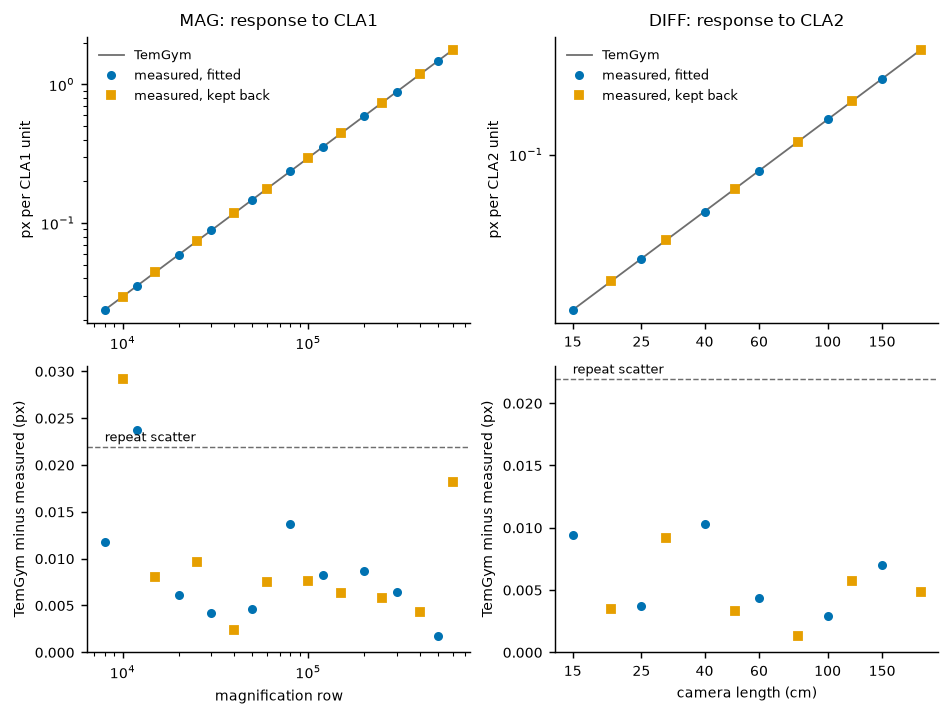

In [16]:
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 130})
BLUE, ORANGE, GREEN, RED, GREY = "#0072B2", "#E69F00", "#009E73", "#D55E00", "#6E6E6E"

figure, panels = plt.subplots(2, 2, figsize=(7.2, 5.4), constrained_layout=True)
for column_index, (mode, deflector, label) in enumerate([("MAG", "CLA1", "magnification row"), ("DIFF", "CLA2", "camera length (cm)")]):
    group = [k for k in recorded if k["mode"] == mode and k["deflector"] == deflector and not k["lens"]]
    seen = np.abs(np.asarray(predicted_response(numbers, as_arrays(group))[0]))
    was_fitted = np.array([is_fitted(k) for k in group])
    labels, measured = np.array([k["row"] for k in group]), np.array([abs(k["along_x"]) for k in group])
    top, bottom = panels[0, column_index], panels[1, column_index]
    top.loglog(labels, seen, "-", color=GREY, lw=1, label="TemGym")
    top.loglog(labels[was_fitted], measured[was_fitted], "o", color=BLUE, ms=4, label="measured, fitted")
    top.loglog(labels[~was_fitted], measured[~was_fitted], "s", color=ORANGE, ms=4, label="measured, kept back")
    top.set(ylabel=f"px per {deflector} unit", title=f"{mode}: response to {deflector}")
    top.legend(frameon=False, fontsize=7)
    miss_x, miss_y = misses(group, numbers)
    bottom.semilogx(labels[was_fitted], miss_x[was_fitted], "o", color=BLUE, ms=4)
    bottom.semilogx(labels[~was_fitted], miss_x[~was_fitted], "s", color=ORANGE, ms=4)
    bottom.axhline(SCATTER_PX, color=GREY, lw=0.8, ls="--")
    bottom.annotate("repeat scatter", (labels[0], SCATTER_PX), xytext=(0, 3), textcoords="offset points", fontsize=7, color="black")
    bottom.set(xlabel=label, ylabel="TemGym minus measured (px)", ylim=(0, None))
    if mode == "DIFF":                                   # few camera lengths: label them plainly
        for axis in (top, bottom):
            axis.set_xticks(labels[::2], [str(v) for v in labels[::2]])
            axis.minorticks_off()
plt.show()

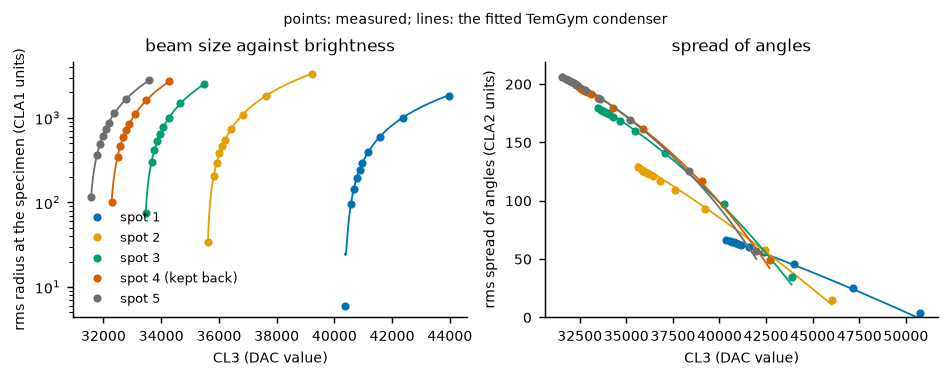

In [17]:
figure, (left, right) = plt.subplots(1, 2, figsize=(7.2, 2.8), constrained_layout=True)
colours = [BLUE, ORANGE, GREEN, RED, GREY]
shown = [(spot, hole) for spot, hole in settings if (spot, hole) in laws and hole == settings[0][1]]
for (spot, hole), colour in zip(shown, colours):
    points = sorted((cl3, b["MAG"]) for (s, h, cl3), b in beams.items() if (s, h) == (spot, hole) and "MAG" in b)
    cl3, radius = np.array(points).T
    fine = np.linspace(cl3.min(), cl3.max(), 300)
    cl1_of_spot = condenser_data["cl1"][condenser_data["spot"] == spot][0]
    model_radius, model_spread, _ = beams_of(condenser_numbers, np.full(300, cl1_of_spot), fine,
                                             np.full(300, holes_used.index(hole)))
    left.semilogy(fine, model_radius, "-", color=colour, lw=1)
    left.semilogy(cl3, radius, "o", color=colour, ms=3.5, label=f"spot {spot + 1}" + (" (kept back)" if spot == KEPT_BACK_SPOT else ""))
    points = sorted((cl3, b["DIFF"]) for (s, h, cl3), b in beams.items() if (s, h) == (spot, hole) and "DIFF" in b)
    wide = np.linspace(points[0][0], points[-1][0], 300)
    model_spread = beams_of(condenser_numbers, np.full(300, cl1_of_spot), wide, np.full(300, holes_used.index(hole)))[1]
    right.plot(wide, model_spread, "-", color=colour, lw=1)
    right.plot(*np.array(points).T, "o", color=colour, ms=3.5)
left.set(xlabel="CL3 (DAC value)", ylabel="rms radius at the specimen (CLA1 units)", title="beam size against brightness")
figure.suptitle("points: measured; lines: the fitted TemGym condenser", fontsize=8)
left.legend(frameon=False, fontsize=7)
right.set(xlabel="CL3 (DAC value)", ylabel="rms spread of angles (CLA2 units)", title="spread of angles", ylim=(0, None))
plt.show()

## 12. The predictor, saved

`results/predictor/projection_model.json`: the fitted projection column's and condenser's numbers. With them,
`predicted_response` gives the response of CLA1 and CLA2 on the camera for any IL1-PL1 values, and `beams_of` the
beam's radius, spread of angles and current for any CL1, CL3 and hole.

In [18]:
folder = Path("results/predictor")
folder.mkdir(parents=True, exist_ok=True)
(folder / "projection_model.json").write_text(json.dumps(dict(
    about="TemGym ElectromagneticLens column (objective, IL1, IL2, IL3, PL1) fitted by fit_predictor.ipynb to "
          f"{RECORDING.name} (record_predictor.py). Lengths at the specimen in CLA1 units, angles in CLA2 units; the "
          "gaps are not the real lens positions. Held: the PL1-to-camera gap and the size of a CLA1 unit.",
    numbers=numbers, repeat_scatter_px=SCATTER_PX, chi2=best["chi2"], dof=best["dof"], pixel_m=PIXEL, voltage_v=VOLTAGE,
    condenser_size_laws={f"spot index {s}, hole {h}": dict(log_smallest=p[0], log_growth=p[1], CL3_at_focus=p[2])
                         for (s, h), p in laws.items()},
    condenser=dict(about="source -> CL1 -> CL3 -> aperture -> one fixed lens -> specimen (section 10); gaps from the "
                         "source, not the real positions. Held: m per CLA1 unit, rad per CLA2 unit, hole 1's radius.",
                   numbers=condenser_numbers, holes=holes_used, m_per_cla1_unit=M_PER_CLA1_UNIT,
                   rad_per_cla2_unit=RAD_PER_CLA2_UNIT, hole_1_radius_m=HOLE_1_RADIUS,
                   ampere_turns_per_unit=CONDENSER_AMPERE_TURNS_PER_UNIT),
), indent=1, default=lambda value: np.asarray(value).tolist()))
print("saved", folder / "projection_model.json")

saved results/predictor/projection_model.json
